# Plot the Variability in the Load Projections for the WECC

This notebook plots a series of evaluation plots show the variability in the ML loads for BAs in the WECC.


In [7]:
# Start by importing the packages we need:
import os
import warnings
import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


## Suppress Future Warnings


In [2]:
# Ignore future warnings:
warnings.simplefilter(action='ignore', category=FutureWarning)


## Set the Directory Structure

In [118]:
# Set the data input directory and output directories:
load_area_data_dir = '/Users/burl878/Documents/Code/code_repos/esp_forecasting_loads/data/load_area_time_series/'
wecc_data_dir = '/Users/burl878/Documents/Code/code_repos/esp_forecasting_loads/data/wecc_time_series/'
image_output_directory =  '/Users/burl878/Documents/Code/code_repos/esp_forecasting_loads/figures/load_variability/'


## Process and Plot the Variability in Peak Demand Across Weather Years


In [119]:
# Define a function to process the extract the peak demand and annual energy for each year:
def process_annual_energy_and_peak_demand(load_area_data_dir: str, wecc_data_dir: str):
    
    #Initiate a counter and empty dataframe to store the results:
    counter = 0;
    output_df = pd.DataFrame()

    # Loop over the years of load data:
    for weather_year in range(1980,2025,1):

        # Make a list of all the load area .csv files in a given directory:
        filelist = glob.glob((load_area_data_dir + str(weather_year) + '/*.csv'))
                
        # Loop over the filelist and extract the data:
        for i in range(len(filelist)):
                               
            # Read in the .csv file and convert the time to a datetime variable:
            temp_df = pd.read_csv(filelist[i])
            temp_df['Time_UTC'] = pd.to_datetime(temp_df['Time_UTC'])
            
            # Add in the load area:
            temp_df['Load_Area'] = os.path.splitext(os.path.basename(str(filelist[i])))[0].replace(".csv", "").replace("_pred", "")
        
            # Concatenate the data from multiple load areas:
            if i == 0:
               load_area_df = temp_df.copy()
            else:
               load_area_df = pd.concat([load_area_df, temp_df])

            # Clean up and move to the next load area:
            del temp_df

        # Sort so I can triage the names:
        load_area_df = load_area_df.sort_values(by=['Load_Area', 'Time_UTC'])

        # Calculate the total load in the WECC by summing hourly loads across load areas:
        load_area_df['WECC_Demand_MWh'] = (load_area_df['Predicted_Demand_MWh'].groupby(load_area_df['Time_UTC']).transform('sum')).round(2)

        # Subset to just the variables we need and drop the duplicate rows:
        wecc_df = load_area_df[['Time_UTC', 'WECC_Demand_MWh']].copy(deep=False).reset_index(drop=True)
        wecc_df = wecc_df.drop_duplicates().reset_index(drop=True)

        # Write out the dataframe to a .csv file:
        wecc_df.to_csv((wecc_data_dir + 'WECC_Loads_' + str(weather_year) + '.csv'), sep=',', index=False)

        # Iterate the counter by one:
        counter = counter + 1

        # Put the output in a new dataframe:
        output_df.loc[counter, 'Weather_Year'] = weather_year
        output_df.loc[counter, 'Annual_Energy_TWh'] = ((wecc_df['WECC_Demand_MWh'].sum()) / 1000000).round(3)
        output_df.loc[counter, 'Peak_Demand_GW'] = ((wecc_df['WECC_Demand_MWh'].max())/1000).round(3)
        output_df.loc[counter, 'Peak_Hour'] = (wecc_df['Time_UTC'].loc[wecc_df['WECC_Demand_MWh'].idxmax()])
        output_df.loc[counter, 'Peak_Day_of_Year'] = output_df.loc[counter, 'Peak_Hour'].day_of_year
    
        # Clean up and move to the next weather year:
        del load_area_df, wecc_df

    # Convert the weather years and peak day of year to integers:
    output_df['Weather_Year'] = output_df['Weather_Year'].astype(int)
    output_df['Peak_Day_of_Year'] = output_df['Peak_Day_of_Year'].astype(int)
       
    # Write out the dataframe to a .csv file:
    output_df.to_csv((wecc_data_dir + 'WECC_Annual_Energy_and_Peak.csv'), sep=',', index=False)
        
    return output_df
    

In [120]:
# Execute the function:
output_df = process_annual_energy_and_peak_demand(load_area_data_dir = load_area_data_dir, 
                                                  wecc_data_dir = wecc_data_dir)

output_df


,Weather_Year,Annual_Energy_TWh,Peak_Demand_GW,Peak_Hour,Peak_Day_of_Year
1,1980,713.450,134.270,1980-07-29 01:00:00,211
2,1981,717.091,128.361,1981-07-21 02:00:00,202
3,1982,710.935,127.348,1982-09-03 01:00:00,246
4,1983,715.215,127.431,1983-07-14 01:00:00,195
5,1984,722.912,127.529,1984-07-06 01:00:00,188
6,1985,719.564,137.152,1985-07-09 01:00:00,190
7,1986,708.965,127.153,1986-08-20 01:00:00,232
8,1987,710.570,122.996,1987-08-05 01:00:00,217
9,1988,719.459,131.025,1988-07-26 01:00:00,208
10,1989,713.987,132.722,1989-07-07 01:00:00,188


## Plot the Annual Variability in Peak Demands and Peak Day of Year


In [121]:
# Define a function to plot the peak load and peak day of year:
def plot_annual_peak_demand(wecc_data_dir: str, image_output_directory: str, image_resolution: int, save_images=False):

    # Read in the data frame processed above:
    wecc_df = pd.read_csv((wecc_data_dir + 'WECC_Annual_Energy_and_Peak.csv'))

    # Make the plot:
    plt.figure(figsize=(15, 15))
    plt.rcParams['font.size'] = 18
    plt.scatter(wecc_df['Peak_Day_of_Year'], wecc_df['Peak_Demand_GW'], s=100, c='blue')
    #plt.legend(loc='upper left')
    plt.xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    plt.xticks(rotation = 45)
    plt.xlim([151, 275])
    plt.ylim([(wecc_df['Peak_Demand_GW'].min()-3), (wecc_df['Peak_Demand_GW'].max()+3)])
    plt.xlabel('Day of the Year for Peak Demand')
    plt.ylabel('Peak Demand in the WECC [GW]')
    plt.title('Interannual Variability in Peak Demand in the WECC')

    # If the "save_images" flag is set to true then save the plot to a .png file:
    if save_images == True:
       plt.savefig(os.path.join(image_output_directory + 'WECC_Peak_Load_Variability.png'), dpi=image_resolution, bbox_inches='tight')
    

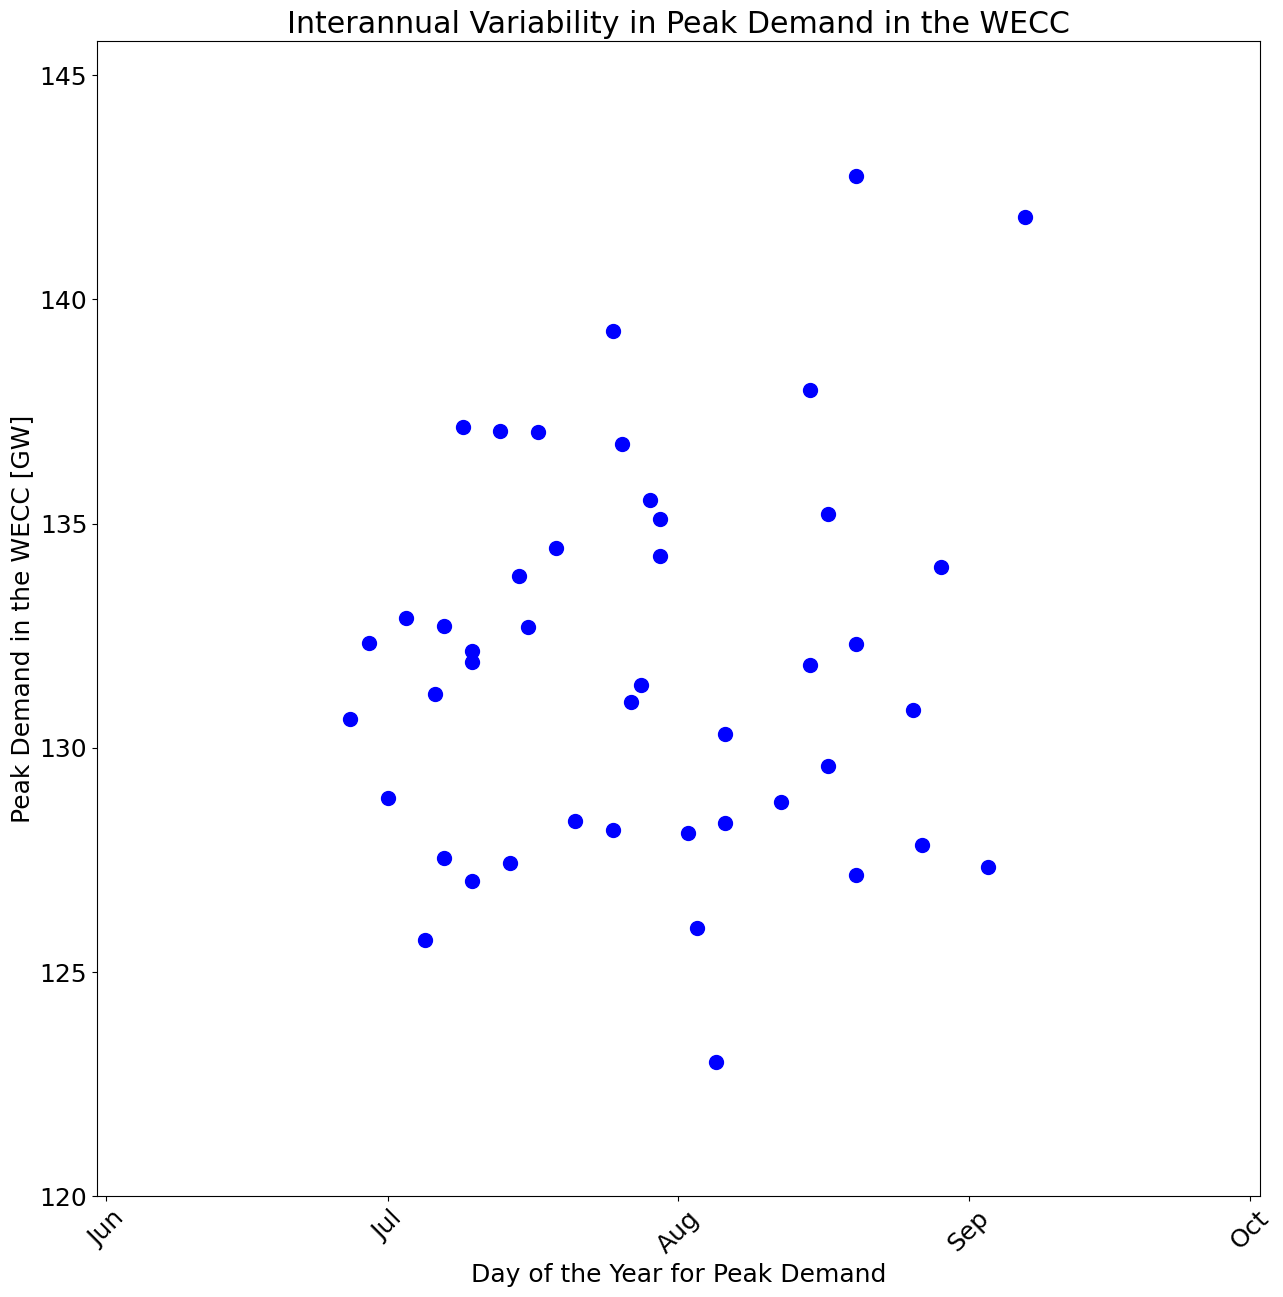

In [123]:
# Execute the function:
plot_annual_peak_demand(wecc_data_dir = wecc_data_dir,
                        image_output_directory = image_output_directory, 
                        image_resolution = 300, 
                        save_images = True)


## Plot the WECC Time Series for a Given Weather Year


In [140]:
# Define a function to plot the time series of WECC loads for a given weather year:
def plot_wecc_load_time_series(weather_year: int, wecc_data_dir: str,                           
                               image_output_directory: str, image_resolution: int, save_images=False):

    # Read in WECC load time series for that weather year and convert the time to a datetime variable:
    wecc_df = pd.read_csv((wecc_data_dir + 'WECC_Loads_' + str(weather_year) + '.csv'))
    wecc_df['Time_UTC'] = pd.to_datetime(wecc_df['Time_UTC'])

    # Calculate the annual statistics:
    annual_energy = (wecc_df['WECC_Demand_MWh'].sum()*0.000001).round(2)
    peak_demand = (wecc_df['WECC_Demand_MWh'].max()*0.001).round(2)
    peak_to_mean_ratio = ((wecc_df['WECC_Demand_MWh'].max()) / (wecc_df['WECC_Demand_MWh'].mean())).round(3)
        
    # Calculate the minimum and maximum values to be used in plotting:
    timemin = wecc_df['Time_UTC'].min()
    timemax = wecc_df['Time_UTC'].max()
    loadmin = 60000
    loadmax = 145000

    # Make the plot:
    plt.figure(figsize=(30, 15))
    plt.rcParams['font.size'] = 18
    plt.plot(wecc_df['Time_UTC'], wecc_df['WECC_Demand_MWh'], color='k', linestyle='-', linewidth=1)
    plt.xlabel('Time [UTC]')
    plt.xlim([timemin, timemax])
    plt.ylabel('Hourly Load [MWh]')
    plt.ylim([loadmin, loadmax])
    plt.title(('WECC Total Loads Loads in Weather Year ' + str(weather_year) + 
               '\n Annual Energy = ' + str(annual_energy) + ' TWh, Peak Demand = ' + str(peak_demand) + ' GW, Peak-to-Mean Ratio = ' + str(peak_to_mean_ratio)))

    # If the "save_images" flag is set to true then save the plot to a .png file:
    if save_images == True:
       plt.savefig(os.path.join(image_output_directory + 'WECC_Loads_' + str(weather_year) + '.png'), dpi=image_resolution, bbox_inches='tight')
       plt.close() 
    

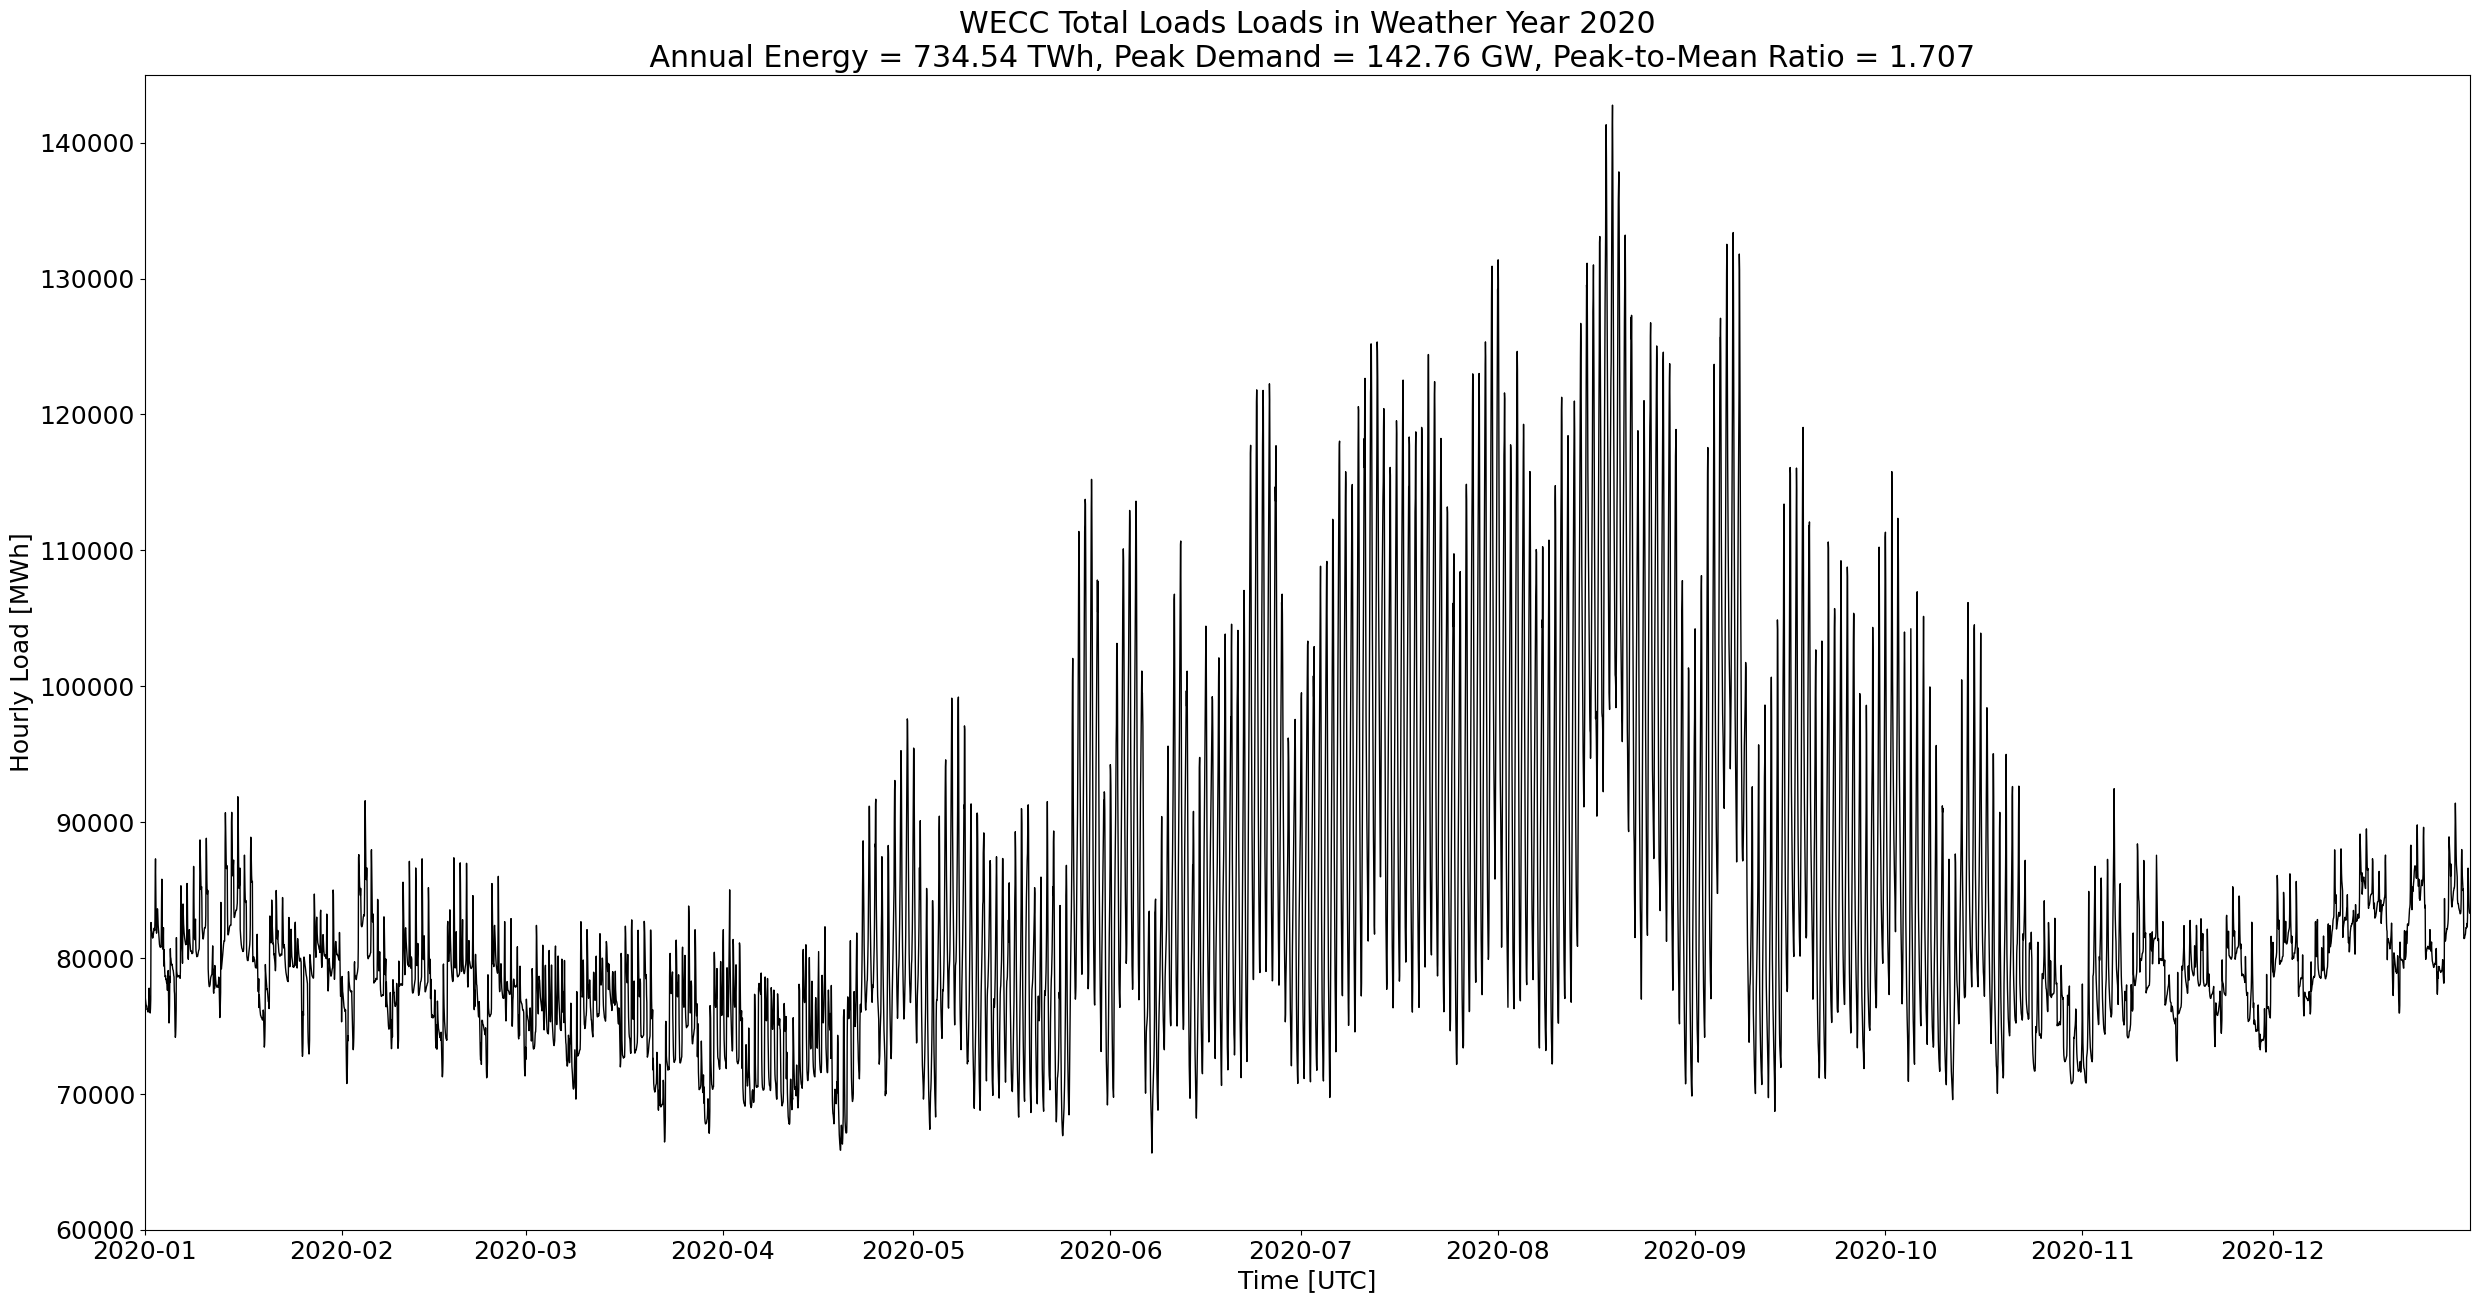

In [144]:
# Test the function:
plot_wecc_load_time_series(weather_year = 2020,
                           wecc_data_dir = wecc_data_dir,
                           image_output_directory = image_output_directory, 
                           image_resolution = 150, 
                           save_images = False)


In [143]:
# Loop over the years of load data and make the time series plot for each year:
for year in range(1980,2025,1):
    plot_wecc_load_time_series(weather_year = year,
                               wecc_data_dir = wecc_data_dir,
                               image_output_directory = image_output_directory, 
                               image_resolution = 150, 
                               save_images = True)
    